In [60]:
from ete3 import Tree
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [61]:
# Global plotting settings
# =========================
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Arial'

In [62]:

#with open('exported_tree_breast.nw', 'r') as f:
#with open('reroot_highest_ref', 'r') as f:
with open('tree_with_node_names.nw', 'r') as f:
    file_content = f.read()
newick_tree = file_content

# Create a tree object
tree = Tree(newick_tree, format = 1)

# Get the root node
root = tree.get_tree_root()

distances_from_root = {}

# Calculate the distance between the root and each leaf node
for leaf in tree.iter_leaves():
    distances_from_root[str(leaf)[3:41]] = root.get_distance(leaf, topology_only=False) #topology true if we only want to know number of ancestors 

In [63]:
signatures_data_frame = pd.read_csv("exposures_custom_signatures.txt", sep="\t")
signatures_data_frame=signatures_data_frame.set_index("Unnamed: 0")
signatures_data_frame.index.name = "Signature"


In [64]:
signatures_data_frame = signatures_data_frame.T

In [65]:
#signatures_data_frame = pd.read_csv("exposures_custom_signatures.txt", sep="\t")
#signatures_data_frame = sig_data
signatures_data_frame_no_0 = signatures_data_frame.loc[:, (signatures_data_frame != 0).any(axis=0)]
#signatures_data_frame_no_0 = signatures_data_frame_no_0.set_index("Samples")
#df_normalized = signatures_data_frame_no_0.div(signatures_data_frame_no_0.sum(axis=1), axis=0).multiply(100)

#signatures_data_frame_no_0 = df_normalized

signature_data = signatures_data_frame_no_0
signature_dict = signature_data.to_dict(orient='index')


In [67]:
data_frame_mutations_all_nodes = pd.read_csv("genotypes_all_nodes.txt", sep="\t")

In [68]:
mutations_dict_all_nodes = {}
dict_just_mut_all_nodes = {}
for i in data_frame_mutations_all_nodes.columns:
    if i == "Site":
        continue
    else: 
        mutations_dict_all_nodes[i] = [0,0,0]
        dict_just_mut_all_nodes[i] = 0

for i in data_frame_mutations_all_nodes.columns:
    if i == "Site":
        continue
    else:
        for j in data_frame_mutations_all_nodes[i]:
            if j == "H": 
                dict_just_mut_all_nodes[i] += 1
                mutations_dict_all_nodes[i][0] += 1
            elif j == "R":
                mutations_dict_all_nodes[i][1] += 1
            else: 
                dict_just_mut_all_nodes[i] += 1
                mutations_dict_all_nodes[i][2] += 1


            # H,R,A

Breast_Cancer_3p_LT_TTTCATGGTTAAGTCC-1 leaf_node
Breast_Cancer_3p_LT_TTTCATGGTTAAGTCC-1 here
zaWCrja here
DDKBiom here
dCoByoY here
usjnCRG here
wlKHZmU here
lBOfXeK here
qUxbjmp here
JDMDKbe here
PZwyBTX here
oXHDFxy here
NGWfQdG here
dnFHxPB here
XttHtoL here
OYyhHCu here
qOdYUbC here
WwQjUQX here
ozwQMEV here
VqnkPRl here
RNxFYss here
olvgjMO here
cDlZLuS here
RNJwNrA here
gbisCxU here
uRBPisP here
WFGtJpa here
bqrYwlo here
uocBbOI here
LmkgdtM here
FtgZOAr here
TRyaxwK here
KoPKQWo here
wVqPOxE here
bTjIIoG here
YEMKwRL here
Waidsvh here
jfyAlFu here
EaSZpMY here
buYPEcD here
NFkKBYY here
JtYWFLP here
ifUlrLO here
YXVkvlX here
GaMLZyT here
OhPxCAa here
LefOxnV here
cQhpiLh here
sHmUXyb here
DlrXHVH here
tLYERRa here
dePWcDW here
hKocyXu here
kxjnjIq here
XpRUadb here
HPsTGtl here
UJtboyI here
fnBEPbs here
iekNifM here
ugSwdeN here
aDNdaAy here
TbFAoKy here
DurXAfk here
QmEqURS here
PybbVwu here
iezFtkZ here
exGQquH here
LiUfOGF here
rTsMZqa here
rPKniRk here
NtRsdWy here
nNHPwaq he

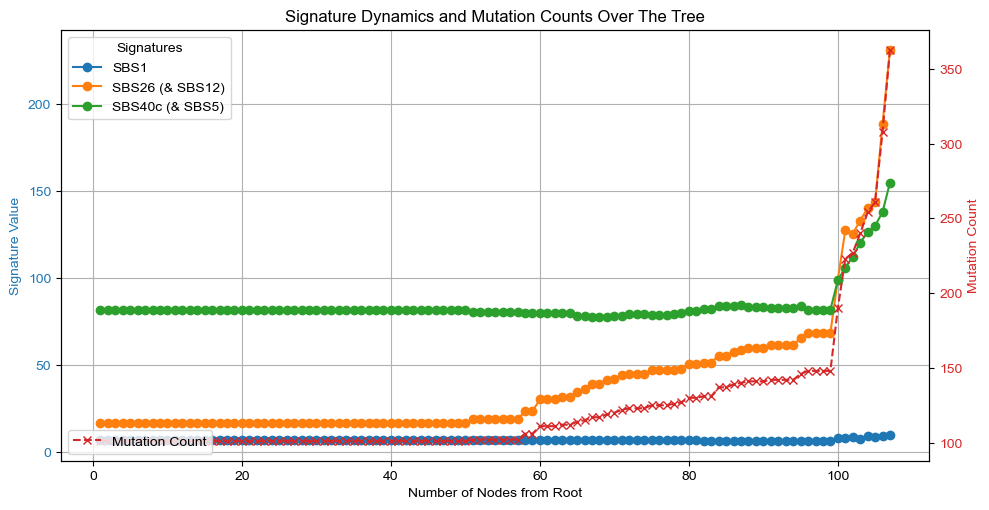

In [ ]:
from ete3 import Tree
import matplotlib.pyplot as plt

# Function to get signatures and number of nodes from the root
def get_ancestor_signatures(leaf_name, tree, signature_dict):
    # Get the leaf node
    leaf_node = tree.search_nodes(name=leaf_name)[0]
    #if leaf_node.is_leaf():
     #   leaf_node = leaf_node.up
    print(leaf_node.name, "leaf_node")
    # Prepare lists for signatures, node counts, and mutation counts
    signatures = []
    node_counts = []  # To store the number of nodes from the root
    mutation_counts = []

    # Traverse up to the root and collect signatures and mutation counts
    current_node = leaf_node
    node_count = 0  # Initialize node count
    while current_node:
        if current_node.name == "":
            current_node = current_node.up
            continue
        else:
            signatures.append(signature_dict.get(current_node.name, {}))  # Get signatures for the node
            mutation_counts.append(dict_just_mut_all_nodes.get(current_node.name, 0))  # Get mutation count
            node_counts.append(node_count + 1)  # Append the node count (steps from root)
            current_node = current_node.up  # Move to the parent
            node_count += 1  # Increment the node count for each step
    return node_counts, signatures[::-1], mutation_counts[::-1]  # Return node counts in order from root to leaf

# Specify the leaf name and the list of signatures you want to plot
leaf_name = "Breast_Cancer_3p_LT_TTTCATGGTTAAGTCC-1"
#leaf_name = "Breast_Cancer_3p_LT_ACAGAAACACCGTGAC-1"
#leaf_name = "Breast_Cancer_3p_LT_ACTATTCTCGAACGCC-1"

# Modify the signature list to group SBS40c with SBS5 and SBS26 with SBS12, and include SBS1
signature_list = ['SBS1', ('SBS26', 'SBS12'), ('SBS40c', 'SBS5')]  # Grouped pairs and SBS1

# Get the signatures and mutation counts for the specified leaf
node_counts, ancestor_signatures, mutation_counts = get_ancestor_signatures(leaf_name, tree, signature_dict)

# Reverse the lists to go from root to leaf
node_counts.reverse()
ancestor_signatures.reverse()
mutation_counts.reverse()

# Print out the node counts, signatures, and mutation counts
for node_count, sig, mut_count in zip(node_counts, ancestor_signatures, mutation_counts):
    print(f"Node Count: {node_count}, Signatures: {sig}, Mutation Count: {mut_count}")

# Step 3: Plot the signature dynamics and mutation counts
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot each group of signatures and SBS1 on the primary y-axis
for group in signature_list:
    if isinstance(group, tuple):  # If it's a pair (grouped signatures)
        # Group the signatures by pair and sum their values
        signature_values = []
        for signature in group:
            signature_values.append([sig.get(signature, 0) for sig in ancestor_signatures])
        # Sum values of each pair and plot together
        summed_values = [sum(x) for x in zip(*signature_values)]
        ax1.plot(node_counts, summed_values, marker='o', label=f"{group[0]} (& {group[1]})")
    else:  # If it's a single signature (like SBS1)
        signature_values = [sig.get(group, 0) for sig in ancestor_signatures]
        ax1.plot(node_counts, signature_values, marker='o', label=group)

# Customize the primary y-axis for signatures
ax1.set_xlabel('Number of Nodes from Root')
ax1.set_ylabel('Signature Value', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid()

# Create a secondary y-axis for mutation counts
ax2 = ax1.twinx()  
ax2.set_ylabel('Mutation Count', color='tab:red')  
ax2.plot(node_counts, mutation_counts, linestyle='--', color='tab:red', marker='x', label='Mutation Count')
ax2.tick_params(axis='y', labelcolor='tab:red')

# Customize the plot with legends and title
fig.tight_layout()  
plt.title('Signature Dynamics and Mutation Counts Over The Tree')
ax1.legend(title='Signatures', loc='upper left')
ax2.legend(loc='lower left')

plt.show()


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


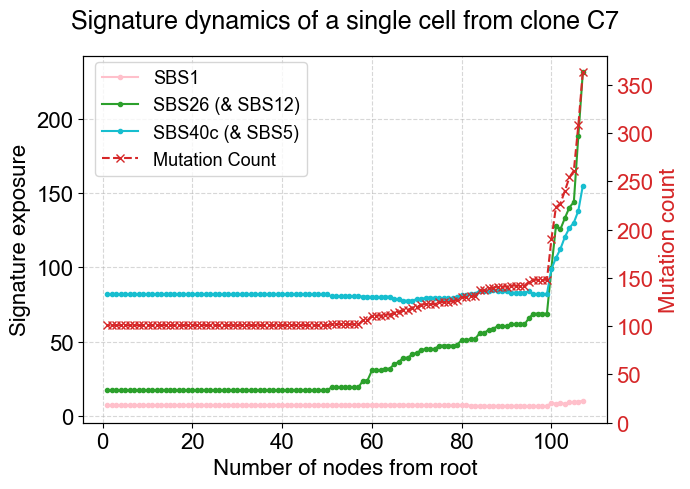

In [109]:
# Custom colors for each line in order (adjust length to number of lines)
custom_colors = ["pink", "tab:green", "tab:cyan"]  # example

fig, ax1 = plt.subplots(figsize=(7, 5))

for i, group in enumerate(signature_list):
    if isinstance(group, tuple):  # grouped signatures
        signature_values = []
        for signature in group:
            signature_values.append([sig.get(signature, 0) for sig in ancestor_signatures])
        summed_values = [sum(x) for x in zip(*signature_values)]
        ax1.plot(node_counts, summed_values, marker='.', label=f"{group[0]} (& {group[1]})", color=custom_colors[i % len(custom_colors)])

    else:  # single signature
        signature_values = [sig.get(group, 0) for sig in ancestor_signatures]
        ax1.plot(node_counts, signature_values, marker='.',
                 label=group,
                 color=custom_colors[i % len(custom_colors)])
        
# Primary y-axis
ax1.set_xlabel('Number of nodes from root', fontsize=16, fontname="Helvetica")
ax1.set_ylabel('Signature exposure', color='black', fontsize=16, fontname="Helvetica")
ax1.tick_params(axis='y', labelcolor='black', labelsize=16)
ax1.tick_params(axis='x', labelsize=16)
ax1.grid(True, linestyle='--', alpha=0.5)

# Secondary y-axis for mutation counts
ax2 = ax1.twinx()
ax2.set_ylabel('Mutation count', color='tab:red', fontsize=16, fontname="Helvetica")
ax2.plot(node_counts, mutation_counts, linestyle='--', color='tab:red', marker='x', label='Mutation Count')
ax2.tick_params(axis='y', labelcolor='tab:red', labelsize=16)
ax2.set_ylim(0,380)

# Title
ax1.set_title('Signature dynamics of a single cell from clone C7',
              fontsize=18, fontname="Helvetica", pad=20)

# Legends
fig.legend(
    loc='center left',
    bbox_to_anchor=(0.13, 0.75),
    fontsize=13,
)

fig.tight_layout()
plt.savefig("signature_dynamics_cloneC7_customcolors_30_dec.pdf", bbox_inches="tight", dpi=600)
plt.show()
